In [6]:
import numpy as np
import pandas as pd
import torch
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from datetime import datetime
from scipy.stats import spearmanr
from scipy.optimize import curve_fit
from matplotlib.ticker import FormatStrFormatter

import sys
sys.path.append("../../tools")
import functions as func

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [7]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8, # axis labels (text)
    'axes.titlesize': 9,
    'axes.linewidth': 0.5, # axis border line width
    'legend.fontsize': 7, # legend (legend content, not legend title)
    'xtick.major.width': 0.5, # tick line width
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5, # tick line length (1.5 is relatively short)
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8, # x-axis tick labels (numbers)
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix', # make math formulas more consistent with Arial

    'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
    'ps.fonttype': 42
})

cmap = LinearSegmentedColormap.from_list(
    "custom_cmap",
    ["#f4f4f4", "#FCB00C"]
)


In [8]:
import importlib
#importlib.reload(eva)
#importlib.reload(prep)
#importlib.reload(func)


In [9]:
# Load models
load_dir1 = Path(f"../../saved_models/sta_entropy_15fold/sp3to20_MD_transpt3_r9")
load_dir2 = Path(f"../../saved_models/diversity_15fold/sp3to20_MD_transpt3_r1")
load_dir4 = Path(f"../../saved_models/fluctuation_15fold_v2/sp3to20_Fl_transpt3_r1")
emodel = func.load_saved_model_MD(load_dir1, device)
dmodel = func.load_saved_model_MD(load_dir2, device)
fmodel = func.load_saved_model_MD(load_dir4, device)
epredictor = func.Predictor(emodel)
dpredictor = func.Predictor(dmodel)
fpredictor = func.Predictor(fmodel)
MaxNum = emodel["NumSpecies"]


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [37]:
df = pd.read_csv(f"../Fig4/random2.csv")
#df = pd.read_csv(f"gamma5.csv")
#df = pd.read_csv(f"../Fig4/random2_upto20.csv")

df = df.dropna()
df = df[df["richness"]>=4]
df["relative_H"] = df["relative_H"].clip(lower=0, upper=1)
df["relative_D"] = df["relative_D"].clip(lower=0, upper=1)


**H versus D**

In [34]:
#sub_df = df[df["fluctuation"]==0]

#sub_df = df[df["pos_inall"]>0.8] # highpos
#sub_df = df[df["pos_inall"]<0.2] # lowpos
#sub_df = df[df["density"]>0.8] # highden
#sub_df = df[df["density"]<0.2] # lowden
#sub_df = df[df["gamma_neg_mean"]>6] # highnegcenter
#sub_df = df[df["gamma_neg_mean"]<2] # lownegcenter

sub_df = df[(df["richness"]==20)]

all_entropy = []
all_diversity = []

for spe, sub in sub_df.groupby("richness"):
    print(f"dealing with richness={spe}")
    Xnum_pad = sub.iloc[:, :(MaxNum**2+MaxNum)].values
    # y_pred = epredictor.predict_array_MD(Xnum_pad, device)
    # entropy = y_pred*(spe-1)+1
    entropy = epredictor.predict_array_MD(Xnum_pad, device)
    diversity = dpredictor.predict_array_MD(Xnum_pad, device)
    entropy = np.clip(entropy, 0, 1)
    diversity = np.clip(diversity, 0, 1)
    all_entropy.append(entropy)
    all_diversity.append(diversity)

all_entropy = np.concatenate(all_entropy)
all_diversity = np.concatenate(all_diversity)


dealing with richness=20.0


**Curve fitting**

*Consider all points*

In [ ]:
import numpy as np
from scipy.optimize import curve_fit

plotx = all_entropy
ploty = all_diversity

def exp_linear(x, a, k, b, c):
    return a * np.exp(-k * x) + b * x + c

# Reciprocal + linear fitting
# y = a / (x + c) + b*x + d
def reciprocal_linear(x, a, c, b, d):
    return a / (x + c) + b * x + d

# Initial parameters
p0 = [0.1, 0.1, 0.5, 0]

params, pcov = curve_fit(
    reciprocal_linear,
    plotx,
    ploty,
    p0=p0,
    maxfev=50000
)

a, c, b, d = params

#x_fit = np.linspace(plotx.min(), plotx.max(), 500)
x_fit = np.linspace(plotx.min(), 1, 1000)
y_fit = reciprocal_linear(x_fit, *params)


Spearman's rho: -0.5609775082562902
Pearson's r: -0.37830744995011223
Fitted function:
D = 0.0029 / (H + 0.0036) + 0.5230 H + 0.0709


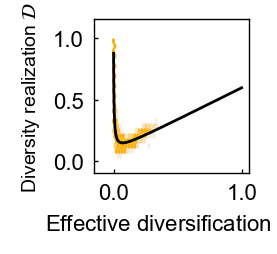

In [105]:
plotx = all_entropy
ploty = all_diversity

plt.figure(figsize=(1,1), dpi=200) 

hb = plt.hexbin(
    plotx, ploty,
    gridsize=25,
    extent=(plotx.min()-0.1, plotx.max()+0.1, ploty.min()-0.1, ploty.max()+0.1),   # xmin, xmax, ymin, ymax
    mincnt=1,
    cmap=cmap,
    vmin=0, vmax=15,
    edgecolors='none',
    rasterized=True
)

# Fitted manifold
plt.plot(
    x_fit,
    y_fit,
    color='black',
    linewidth=1.0,
    zorder=10
)

# plt.fill_between(
#     x_fit,
#     y_lower,
#     y_upper,
#     color='black',
#     alpha=0.15,
#     linewidth=0.5,
#     zorder=9
# )

# Original formatting
plt.gca().xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
plt.gca().yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

spear = spearmanr(plotx, ploty).correlation
pear = np.corrcoef(plotx, ploty)[0, 1]

print(f"Spearman's rho: {spear}")
print(f"Pearson's r: {pear}")

print(
    f"Fitted function:\n"
    f"D = {a:.4f} / (H + {c:.4f}) "
    f"+ {b:.4f} H + {d:.4f}"
)

plt.xlabel(r"Effective diversification $\mathcal{H}$",)
plt.ylabel(r"Diversity realization $\mathcal{D}$", fontsize=7)

plt.tick_params(direction='in')

plt.savefig(
    f"H-D_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches='tight',
    transparent=True
)

plt.show()


*Fit lower bound*

In [ ]:
import numpy as np
from scipy.optimize import minimize
from scipy.stats import binned_statistic_2d
from matplotlib.ticker import FormatStrFormatter

plotx = np.asarray(all_entropy)
ploty = np.asarray(all_diversity)

# 1. Compute 2D local density
nx = 25
ny = 25

density, x_edge, y_edge, _ = binned_statistic_2d(
    plotx, ploty, None,
    statistic='count', bins=[nx, ny]
)

ix = np.digitize(plotx, x_edge) - 1
iy = np.digitize(ploty, y_edge) - 1

valid = ((ix >= 0) & (ix < nx) & (iy >= 0) & (iy < ny))

# 2. Weight each point by local density
#    alpha = 0.5 -> 1/sqrt(n)
alpha = 0.5
weights = np.zeros_like(plotx, dtype=float)
weights[valid] = (1 / density[ix[valid], iy[valid]] ** alpha)

# Normalize so mean weight ~ 1
weights *= len(weights) / weights.sum()

# 3. reciprocal + linear
def reciprocal_linear(x, c, b, d):
    return 0.01 / (x + c) + b * x + d

# 4. Weighted quantile loss
def quantile_loss(params, x, y, q, weights):

    pred = reciprocal_linear(x, *params)
    residual = y - pred
    loss = np.where(residual >= 0, q * residual, (q - 1) * residual)

    return np.sum(weights * loss)

# 5. Quantile fitting function
def fit_quantile(x, y, q, weights, p0=[0.1, 0.5, 0]):
    result = minimize(
        quantile_loss, p0,
        args=(x, y, q, weights),
        method='Nelder-Mead',
        options={'maxiter': 50000}
    )
    return result.x

# 6. Fit lower bound
params_lower = fit_quantile(plotx, ploty, q=0.05, weights=weights)


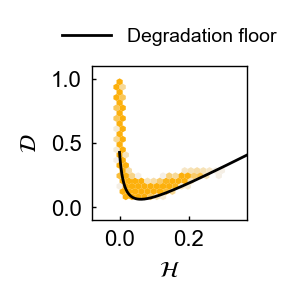

In [36]:
plotx = np.asarray(all_entropy)
ploty = np.asarray(all_diversity)

plt.figure(figsize=(1, 1), dpi=200)

hb = plt.hexbin(
    plotx, ploty, gridsize=25,
    extent=(plotx.min()-0.1, plotx.max()+0.1, ploty.min()-0.1, ploty.max()+0.1),
    mincnt=1, cmap=cmap,
    vmin=0, vmax=15,
    edgecolors='none',
    rasterized=True,
)

x_fit = np.linspace(plotx.min(), 1, 800)
y_fit_lower = reciprocal_linear(x_fit, *params_lower)

# Lower bound (black)
plt.plot(
    x_fit, y_fit_lower,
    color='black',
    linewidth=1,
    label='Degradation floor',
)

plt.legend(
    frameon=False,
    handlelength=2.5,
    loc='lower center',
    bbox_to_anchor=(0.5, 1.02)
)

# 8. Plot formatting
plt.gca().xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
plt.gca().yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

plt.xlabel(r"$\mathcal{H}$")
plt.ylabel(r"$\mathcal{D}$")
plt.xlim(-0.1, plotx.max()+0.1)
plt.ylim(-0.1, ploty.max()+0.1)
plt.tick_params(direction='in')

plt.savefig(
    f"H-D_fititself_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches='tight',
    transparent=True
)


*Fit both higher and lower bound*

In [20]:
import numpy as np
from scipy.optimize import minimize
from scipy.stats import binned_statistic_2d
from matplotlib.ticker import FormatStrFormatter

plotx = np.asarray(all_entropy)
ploty = np.asarray(all_diversity)

# 1. Compute 2D local density
nx = 25
ny = 25

density, x_edge, y_edge, _ = binned_statistic_2d(
    plotx, ploty, None,
    statistic='count', bins=[nx, ny]
)

ix = np.digitize(plotx, x_edge) - 1
iy = np.digitize(ploty, y_edge) - 1

valid = ((ix >= 0) & (ix < nx) & (iy >= 0) & (iy < ny))

# 2. Weight each point by local density
#    alpha = 0.5 -> 1/sqrt(n)
alpha = 0.5
weights = np.zeros_like(plotx, dtype=float)
weights[valid] = (1 / density[ix[valid], iy[valid]] ** alpha)

# Normalize so mean weight ~ 1
weights *= len(weights) / weights.sum()

# 3. reciprocal + linear
def reciprocal_linear(x, c, b, d):
    return 0.01 / (x + c) + b * x + d

# 4. Weighted quantile loss
def quantile_loss(params, x, y, q, weights):

    pred = reciprocal_linear(x, *params)
    residual = y - pred
    loss = np.where(residual >= 0, q * residual, (q - 1) * residual)

    return np.sum(weights * loss)

# 5. Quantile fitting function
def fit_quantile(x, y, q, weights, p0=[0.1, 0.5, 0]):
    result = minimize(
        quantile_loss, p0,
        args=(x, y, q, weights),
        method='Nelder-Mead',
        options={'maxiter': 50000}
    )
    return result.x

# 6. Fit lower bound and median
params_lower = fit_quantile(plotx, ploty, q=0.05, weights=weights)
params_upper = fit_quantile(plotx, ploty, q=0.5, weights=weights)


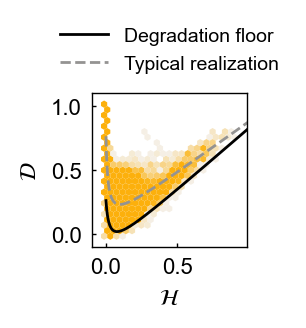

In [21]:
plotx = np.asarray(all_entropy)
ploty = np.asarray(all_diversity)

plt.figure(figsize=(1, 1), dpi=200)

hb = plt.hexbin(
    plotx, ploty, gridsize=25,
    extent=(plotx.min()-0.1, plotx.max()+0.1, ploty.min()-0.1, ploty.max()+0.1),
    mincnt=1, cmap=cmap,
    vmin=0, vmax=15,
    edgecolors='none',
    rasterized=True,
)

x_fit = np.linspace(plotx.min(), 1, 800)

y_fit_lower = reciprocal_linear(x_fit, *params_lower)
y_fit_upper = reciprocal_linear(x_fit, *params_upper)

# Lower bound (black)
plt.plot(
    x_fit, y_fit_lower,
    color='black',
    linewidth=1,
    label='Degradation floor',
)

# Upper bound (gray)
plt.plot(
    x_fit, y_fit_upper,
    color="#949392",
    linewidth=1,
    linestyle='--',
    label='Typical realization',
)

plt.legend(
    frameon=False,
    handlelength=2.5,
    loc='lower center',
    bbox_to_anchor=(0.5, 1.02)
)

# 8. Plot formatting
plt.gca().xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
plt.gca().yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

plt.xlabel(r"$\mathcal{H}$")
plt.ylabel(r"$\mathcal{D}$")
plt.xlim(-0.1, plotx.max()+0.1)
plt.ylim(-0.1, ploty.max()+0.1)
plt.tick_params(direction='in')

plt.savefig(
    f"H-D_fititself_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches='tight',
    transparent=True
)


*Draw y=x guideline*

Spearman's rho: -0.17726613741402003
Pearson's r: -0.013297622991707343


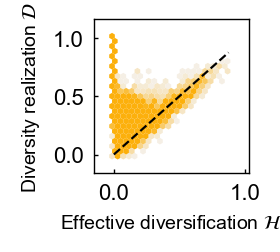

In [121]:
plotx = all_entropy
ploty = all_diversity
# plotx = np.log(all_diversity-all_entropy)
# ploty = np.log(np.log(np.log(1/all_entropy)))
# plotx = 0.0023/(all_entropy+0.0031)+0.4731*all_entropy+0.1119
# ploty = all_diversity

plt.figure(figsize=(1,1), dpi=200)

hb = plt.hexbin(
    plotx,
    ploty,
    gridsize=25, # number of hexagons
    #extent=(0.9, 5.1, -0.1, 1.1),   # xmin, xmax, ymin, ymax
    #extent=(-0.1, 1.1, -0.1, 1.1),   # xmin, xmax, ymin, ymax
    extent=(plotx.min()-0.1, plotx.max()+0.1, ploty.min()-0.1, ploty.max()+0.1),   # xmin, xmax, ymin, ymax
    mincnt=1, # minimum count in each hexagon
    cmap=cmap,
    vmin=0,
    vmax=15, # maximum count in each hexagon
    edgecolors='none',
    # alpha=0.8,
    rasterized=True
)

x_line = np.linspace(plotx.min(), plotx.max(), 500)
plt.plot(x_line, x_line, color='black', linewidth=0.8, linestyle='--')

# cbar = plt.colorbar(hb)
# cbar.set_label("Count")

#plt.xlim(0.1, 7)
#plt.ylim(0, 1)

# plt.xticks([0, all_entropy.max()])
# plt.yticks([0, 0.5, 1])

plt.gca().xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
plt.gca().yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

spear=spearmanr(plotx, ploty).correlation # monotonicity
pear=np.corrcoef(plotx, ploty)[0, 1] # linearity
print(f"Spearman's rho: {spear}")
print(f"Pearson's r: {pear}")

plt.xlabel(r"Effective diversification $\mathcal{H}$",fontsize=7)
#plt.ylabel(r"Relative diversity $\bar{\mathcal{D}}$",fontsize=7)
plt.ylabel(r"Diversity realization $\mathcal{D}$",fontsize=7)
plt.tick_params(direction='in')
#plt.savefig(f"H-D_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf", dpi=1000, bbox_inches='tight', transparent=True)
plt.show()


**Limit of Curve**

dealing with richness=4, n=8000
dealing with richness=5, n=8000
dealing with richness=6, n=8000
dealing with richness=7, n=8000
dealing with richness=8, n=8000
dealing with richness=9, n=8000
dealing with richness=10, n=8000
dealing with richness=11, n=8000
dealing with richness=12, n=8000
dealing with richness=13, n=8000
dealing with richness=14, n=8000
dealing with richness=15, n=8000
dealing with richness=16, n=8000
dealing with richness=17, n=8000
dealing with richness=18, n=8000
dealing with richness=19, n=8000
dealing with richness=20, n=8000

Lower boundary: S -> infinity
c_inf = 0.00329756
b_inf = 1.01493
d_inf = -0.0935466

Medium: S -> infinity
c_inf = 0.0112684
b_inf = 1.10441
d_inf = -0.104291


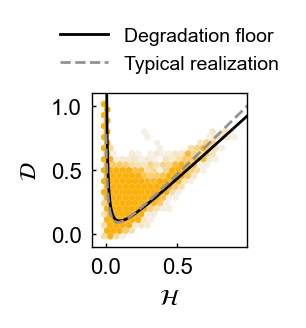

In [22]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from scipy.stats import binned_statistic_2d
from matplotlib.ticker import FormatStrFormatter

# 1. reciprocal + linear model
def reciprocal_linear(x, c, b, d):
    return 0.01 / (x + c) + b * x + d

# 2. Remove 2D density bias
'''
alpha = 0:
    No density correction
alpha = 0.5:
    1 / sqrt(n), mild density correction
alpha = 1:
    1 / n, full density correction
'''
def get_density_weights(x, y, nx=25, ny=25, alpha=0.5):

    x = np.asarray(x)
    y = np.asarray(y)

    # Count local points in 2D grid
    density, x_edge, y_edge, _ = binned_statistic_2d(
        x, y, None,
        statistic='count',
        bins=[nx, ny]
    )

    # Find bin for each point
    ix = np.searchsorted(x_edge, x, side='right') - 1
    iy = np.searchsorted(y_edge, y, side='right') - 1

    # Clip points exactly on upper boundary
    ix = np.clip(ix, 0, nx - 1)
    iy = np.clip(iy, 0, ny - 1)

    local_density = density[ix, iy]

    # Weight by local density
    weights = local_density ** (-alpha)

    # Normalize so mean weight = 1
    weights *= len(weights) / np.sum(weights)

    return weights

# 3. quantile loss
def quantile_loss(params, x, y, q, weights):

    pred = reciprocal_linear(x, *params)
    residual = y - pred
    loss = np.where(residual >= 0, q * residual, (q - 1) * residual)

    return np.sum(weights * loss)

# 4. Quantile fitting at a single richness
def fit_quantile(x, y, q, weights, p0=None):

    if p0 is None:
        p0 = [0.1, 0.5, 0]

    result = minimize(
        quantile_loss, p0,
        args=(x, y, q, weights),
        method='Nelder-Mead',
        options={'maxiter': 50000}
    )

    if not result.success:
        print(
            f"quantile={q}: "
            f"optimization warning: {result.message}"
        )

    return result.x

# 5. Asymptotic fit: richness -> parameter
'''
p(S) = p_inf + k / S
S -> infinity :
p(S) -> p_inf
'''

def asymptotic_function(S, p_inf, k):
    return p_inf + k / S

def fit_richness_asymptote(richness, parameter_values):

    richness = np.asarray(richness, dtype=float)
    parameter_values = np.asarray(parameter_values, dtype=float)
    x = 1.0 / richness
    k, p_inf = np.polyfit(x, parameter_values, 1) # parameter = p_inf + k * (1 / S)

    return p_inf, k

# =========================================================
# 6. Fit richness -> infinity for all reciprocal parameters
# Parameter order:
# [c, b, d]
# =========================================================

def fit_parameter_limits(richness_values, parameter_matrix):

    richness_values = np.asarray(richness_values, dtype=float)
    parameter_matrix = np.asarray(parameter_matrix, dtype=float)
    limit_params = np.zeros(parameter_matrix.shape[1])
    slope_params = np.zeros(parameter_matrix.shape[1])

    for i in range(parameter_matrix.shape[1]):

        p_inf, k = fit_richness_asymptote(richness_values, parameter_matrix[:, i])
        limit_params[i] = p_inf
        slope_params[i] = k

    return limit_params, slope_params

# 7. Richness loop
sub_df = df[(df["richness"] >= 4) & (df["richness"] <= 20)]

lower_params_all = []
upper_params_all = []
richness_all = []

# Use previous richness result as initial guess for next
p0_lower = None
p0_upper = None

for spe in range(4, 21):

    sub = sub_df[sub_df["richness"] == spe]

    if len(sub) == 0:
        print(f"richness={spe}: no samples, skipped")
        continue

    print(
        f"dealing with richness={spe}, "
        f"n={len(sub)}"
    )

    # GLV parameter input
    Xnum_pad = sub.iloc[:, :(MaxNum**2 + MaxNum)].values

    # Predict emergent properties
    entropy = epredictor.predict_array_MD(Xnum_pad, device)
    diversity = dpredictor.predict_array_MD(Xnum_pad, device)
    entropy = np.clip(entropy, 0, 1)
    diversity = np.clip(diversity, 0, 1)
    entropy = np.asarray(entropy).reshape(-1)
    diversity = np.asarray(diversity).reshape(-1)

    # Remove NaN / inf
    valid = (np.isfinite(entropy) & np.isfinite(diversity))
    entropy = entropy[valid]
    diversity = diversity[valid]

    # Remove 2D density bias
    weights = get_density_weights(entropy, diversity, nx=25, ny=25, alpha=0.5)

    # lower bound
    params_lower = fit_quantile(entropy, diversity, q=0.05, weights=weights, p0=p0_lower)
    # upper bound
    params_upper = fit_quantile(entropy, diversity, q=0.5, weights=weights, p0=p0_upper)

    richness_all.append(spe)

    lower_params_all.append(params_lower)
    upper_params_all.append(params_upper)

    # Use current result as initial guess for next richness
    p0_lower = params_lower
    p0_upper = params_upper

# 8. Convert to matrix
richness_all = np.asarray(richness_all, dtype=float)
lower_params_all = np.asarray(lower_params_all)
upper_params_all = np.asarray(upper_params_all)

# 9. richness -> infinity
lower_params_inf, lower_slopes = fit_parameter_limits(richness_all, lower_params_all)
upper_params_inf, upper_slopes = fit_parameter_limits(richness_all, upper_params_all)

# 10. Print limit parameters
parameter_names = ["c", "b", "d"]

print("\n========================================")
print("Lower boundary: S -> infinity")
print("========================================")

for name, value in zip(parameter_names, lower_params_inf):
    print(f"{name}_inf = {value:.6g}")

print("\n========================================")
print("Medium: S -> infinity")
print("========================================")

for name, value in zip(parameter_names, upper_params_inf):
    print(f"{name}_inf = {value:.6g}")

# 11. Build two curves at S -> infinity
x_fit = np.linspace(0, 1, 500)

y_fit_lower_inf = reciprocal_linear(x_fit, *lower_params_inf)
y_fit_upper_inf = reciprocal_linear(x_fit, *upper_params_inf)

# 12. Plot final S -> infinity results
plt.figure(figsize=(1, 1), dpi=200)
plt.plot(x_fit, y_fit_lower_inf, color='black', linewidth=1, label='Degradation floor',)
plt.plot(x_fit, y_fit_upper_inf, color="#949392", linewidth=1, linestyle='--', label='Typical realization',)
plt.legend(
    frameon=False,
    handlelength=2.5,
    loc='lower center',
    bbox_to_anchor=(0.5, 1.02)
)

# 13. Draw heatmap at certain richness (e.g., richness=20)
plotx = np.asarray(all_entropy)
ploty = np.asarray(all_diversity)

hb = plt.hexbin(
    plotx, ploty,
    gridsize=25,
    extent=(plotx.min()-0.1, plotx.max()+0.1, ploty.min()-0.1, ploty.max()+0.1),
    mincnt=1,
    cmap=cmap,
    vmin=0, vmax=15,
    edgecolors='none',
    rasterized=True,
)

plt.xlim(-0.1, plotx.max()+0.1)
plt.ylim(-0.1, ploty.max()+0.1)
plt.gca().xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
plt.gca().yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
plt.xlabel(r"$\mathcal{H}$")
plt.ylabel(r"$\mathcal{D}$")
plt.tick_params(direction='in')
# plt.savefig(
#     f"H-D_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
#     dpi=1000,
#     bbox_inches='tight',
#     transparent=True
# )
plt.show()


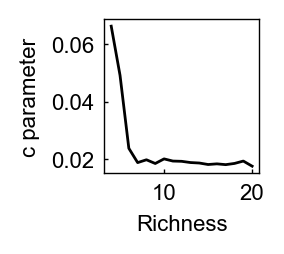

In [23]:
plt.figure(figsize=(1, 1), dpi=200)
#plt.plot(np.arange(4,21), upper_params_all[:,0], color='gray', linewidth=1, linestyle='--')
plt.plot(np.arange(4,21), lower_params_all[:,0], color='black', linewidth=1)
plt.xlabel("Richness")
plt.ylabel("c parameter")
plt.tick_params(direction='in')
plt.savefig(
    f"H-D_para_c_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches='tight',
    transparent=True
)

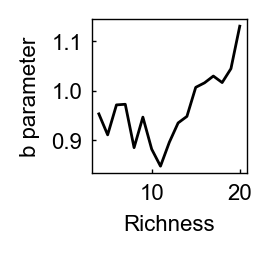

In [24]:
plt.figure(figsize=(1, 1), dpi=200)
#plt.plot(np.arange(4,21), upper_params_all[:,1], color='gray', linewidth=1, linestyle='--')
plt.plot(np.arange(4,21), lower_params_all[:,1], color='black', linewidth=1)
plt.xlabel("Richness")
plt.ylabel("b parameter")
plt.tick_params(direction='in')
plt.savefig(
    f"H-D_para_b_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches='tight',
    transparent=True
)

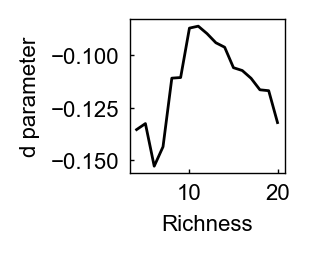

In [25]:
plt.figure(figsize=(1, 1), dpi=200)
#plt.plot(np.arange(4,21), upper_params_all[:,2], color='gray', linewidth=1, linestyle='--')
plt.plot(np.arange(4,21), lower_params_all[:,2], color='black', linewidth=1)
plt.xlabel("Richness")
plt.ylabel("d parameter")
plt.tick_params(direction='in')
plt.savefig(
    f"H-D_para_d_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches='tight',
    transparent=True
)

**Relationship between richness and spearman of H&D**

In [38]:
sub_df = df[
    (df["richness"] >= 4) &
    (df["richness"] <= 20)
]

richness_list = []
spearman_list = []

all_entropy_dict = {}
all_diversity_dict = {}

for spe in range(4, 21):

    sub = sub_df[sub_df["richness"] == spe]

    if len(sub) == 0:
        print(f"richness={spe}: no samples, skipped")
        continue

    print(f"dealing with richness={spe}, n={len(sub)}")

    # GLV parameter input
    Xnum_pad = sub.iloc[:, :(MaxNum**2 + MaxNum)].values

    # Predict emergent properties
    entropy = epredictor.predict_array_MD(Xnum_pad, device)
    diversity = dpredictor.predict_array_MD(Xnum_pad, device)
    entropy = np.clip(entropy, 0, 1)
    diversity = np.clip(diversity, 0, 1)
    entropy = np.asarray(entropy).reshape(-1)
    diversity = np.asarray(diversity).reshape(-1)

    # Save
    all_entropy_dict[spe] = entropy
    all_diversity_dict[spe] = diversity

    rho, p_value = spearmanr(entropy, diversity)

    richness_list.append(spe)
    spearman_list.append(rho)

    print(
        f"    n = {len(entropy)}, "
        f"Spearman rho = {rho:.4f}, "
        f"p = {p_value:.3e}"
    )


dealing with richness=4, n=8000
    n = 8000, Spearman rho = 0.0588, p = 1.423e-07
dealing with richness=5, n=8000
    n = 8000, Spearman rho = -0.0858, p = 1.498e-14
dealing with richness=6, n=8000
    n = 8000, Spearman rho = -0.1787, p = 2.108e-58
dealing with richness=7, n=8000
    n = 8000, Spearman rho = -0.2580, p = 7.584e-122
dealing with richness=8, n=8000
    n = 8000, Spearman rho = -0.3151, p = 6.886e-184
dealing with richness=9, n=8000
    n = 8000, Spearman rho = -0.3351, p = 3.217e-209
dealing with richness=10, n=8000
    n = 8000, Spearman rho = -0.3572, p = 1.904e-239
dealing with richness=11, n=8000
    n = 8000, Spearman rho = -0.4263, p = 0.000e+00
dealing with richness=12, n=8000
    n = 8000, Spearman rho = -0.4294, p = 0.000e+00
dealing with richness=13, n=8000
    n = 8000, Spearman rho = -0.4539, p = 0.000e+00
dealing with richness=14, n=8000
    n = 8000, Spearman rho = -0.4906, p = 0.000e+00
dealing with richness=15, n=8000
    n = 8000, Spearman rho = -0.510

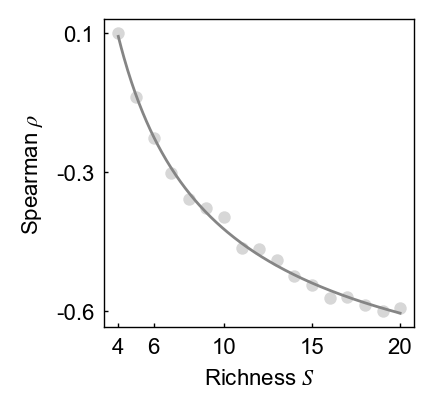

In [41]:
richness_array = np.asarray(richness_list)
spearman_array = np.asarray(spearman_list)

def inverse_power_func(x, a, b, p):
    return b + a / (x ** p)

popt, pcov = curve_fit(
    inverse_power_func,
    richness_array,
    spearman_array,
    p0=[-1, -0.5, 1],
    bounds=([-np.inf, -1, 0], [np.inf, 1, 10])
)

a, b, p = popt

x_fit = np.linspace(richness_array.min(), richness_array.max(), 300)
y_fit = inverse_power_func(x_fit, a, b, p)
y_pred = inverse_power_func(richness_array, a, b, p)
ss_res = np.sum((spearman_array - y_pred) ** 2)
ss_tot = np.sum((spearman_array - np.mean(spearman_array)) ** 2)
r2 = 1 - ss_res / ss_tot

plt.figure(figsize=(2, 2), dpi=200)

# scatter
plt.scatter(
    richness_array,
    spearman_array,
    s=20,
    alpha=0.7,
    color="#C6C6C6",
    linewidths=0
)

# inverse fitting curve
plt.plot(
    x_fit,
    y_fit,
    color="#858585",
    linewidth=1.0
)

plt.xlabel(r"Richness $S$")
plt.ylabel(r"Spearman $\rho$")

plt.tick_params(direction='in')

# fitting information
# plt.text(
#     0.95,
#     0.95,
#     rf"$\rho={b:.2f}+{a:.2f}/S^{{{p:.2f}}}$" "\n"
#     rf"$R^2={r2:.2f}$",
#     transform=plt.gca().transAxes,
#     ha='right',
#     va='top'
# )

plt.xticks([4, 6, 10, 15, 20])
y_min = spearman_array.min()
y_max = spearman_array.max()
y_mid = (y_min + y_max) / 2
plt.yticks([y_min, y_mid, y_max], [f"{y_min:.1f}", f"{y_mid:.1f}", f"{y_max:.1f}"])

plt.savefig(
    f"H-D_richness-spearman_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches='tight',
    transparent=True
)

plt.show()
